In [ ]:
import torch.optim as optim
from torch import nn

In [ ]:
import torch
from torch.utils.data import Dataset,DataLoader
from torchvision import datasets,transforms

transform = transforms.ToTensor() # image to tensor transformation

train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)

# batch loading
train_loader = DataLoader(
    train_data, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_data, batch_size=64, shuffle=False
)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 204kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.77MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.4MB/s]


In [ ]:
img,label = train_data[6]
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}
labels_map[label]

'Sneaker'

In [ ]:
class Model(nn.Module):

  def __init__(self):
    super().__init__()
    self.flatten_layer = nn.Flatten() # convert tensor into 1D
    self.linear_relu_stack = nn.Sequential(
        nn.Linear(28*28,512),
        nn.ReLU(),
        nn.Linear(512,512),
        nn.ReLU(),
        nn.Linear(512,10)
    )

  # forward pass
  def forward(self,x):
    x = self.flatten_layer(x)
    logits = self.linear_relu_stack(x)
    return logits

In [ ]:
model = Model()

criterion = nn.CrossEntropyLoss() # loss function
optimizer = optim.Adam(model.parameters(),lr=0.01) # optimizer

In [ ]:
epochs = 25
for epoch in range(epochs):
  model.train() # model in tranining mode
  running_loss = 0.0

  for images,labels in train_loader:
    # forward pass
    outputs = model(images)
    loss = criterion(outputs,labels)

    # backward pass
    optimizer.zero_grad() # remove previous gradient
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
avg_loss = running_loss / len(train_loader)
print(
        f"Epoch [{epoch + 1}/{epochs}], "
        f"Loss: {avg_loss:.4f}"
    )


Epoch [25/25], Loss: 0.3180


In [ ]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
  for images,labels in test_loader:
    outputs = model(images)
    predictions = outputs.argmax(dim=1)

    total += labels.size(0)
    correct += (predictions == labels).sum().item()

accuracy = 100 * correct / total
print(f"Test Accuracy: {accuracy:.2f}%")



Test Accuracy: 86.33%


In [ ]:
image, true_lable = test_data[0]

model.eval()
with torch.no_grad():
  output = model(image.unsqueeze(0))
  predicted_lable = output.argmax(dim=1).item()

print("Predicted class:", labels_map[predicted_lable])
print("Actual class:", labels_map[true_lable])

Predicted class: Ankle Boot
Actual class: Ankle Boot


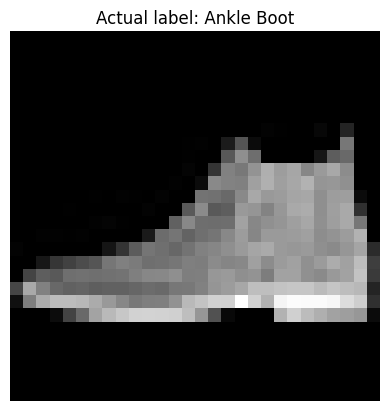

In [ ]:
import matplotlib.pyplot as plt

image, true_label = test_data[0]

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Actual label: {labels_map[true_label]}")
plt.axis("off")
plt.show()

In [ ]:
torch.save(model.state_dict(), "fashion_model.pth")